In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv"
)

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

df_clean = df[features + [target]].copy()

df_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,NaN,NaN,NaN,NaN,Adelie
4,36.7,19.3,193.0,3450.0,Adelie


In [4]:
df_clean[features] = df_clean[features].fillna(
    df_clean[features].median()
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64


In [5]:
le = LabelEncoder()

df_clean[target] = le.fit_transform(df_clean[target])

print("Classes:", le.classes_)
print("Encoded values:", np.unique(df_clean[target]))

Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Encoded values: [0 1 2]


In [6]:
X = df_clean[features].values
y = df_clean[target].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (344, 4)
y shape: (344,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (275, 4)
X_test: (69, 4)
y_train: (275,)
y_test: (69,)


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data mean:", X_train.mean(axis=0))
print("Training data std:", X_train.std(axis=0))

Training data mean: [-3.56563264e-15  5.63428092e-15  3.73438654e-16  1.00929366e-16]
Training data std: [1. 1. 1. 1.]


In [9]:
def rbf_kernel(X1, X2, gamma=0.25):
    X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
    X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)

    distances = X1_sq + X2_sq - 2 * X1 @ X2.T
    distances = np.maximum(distances, 0)

    return np.exp(-gamma * distances)


gamma = 1 / X_train.shape[1]

K_train = rbf_kernel(X_train, X_train, gamma)
K_test = rbf_kernel(X_test, X_train, gamma)

print("K_train shape:", K_train.shape)
print("K_test shape:", K_test.shape)

K_train shape: (275, 275)
K_test shape: (69, 275)


In [10]:
classes = np.unique(y_train)

Y_train = np.where(
    y_train.reshape(-1, 1) == classes.reshape(1, -1),
    1,
    -1
)

print("Y_train shape:", Y_train.shape)
print("Unique values:", np.unique(Y_train))

Y_train shape: (275, 3)
Unique values: [-1  1]


In [12]:
def predict_scores(K, alpha, bias):
    return K @ alpha + bias


def calculate_loss(K, Y, alpha, bias, lambda_reg):
    scores = predict_scores(K, alpha, bias)

    margins = 1 - Y * scores
    hinge_loss = np.maximum(0, margins).mean()

    regularization = 0.5 * lambda_reg * np.sum(
        alpha * (K @ alpha)
    )

    total_loss = hinge_loss + regularization

    return total_loss

In [14]:
learning_rate = 0.001
epochs = 500
lambda_reg = 0.01

beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

n_samples = K_train.shape[0]
n_classes = Y_train.shape[1]

alpha = np.zeros((n_samples, n_classes))
bias = np.zeros(n_classes)

m_alpha = np.zeros_like(alpha)
v_alpha = np.zeros_like(alpha)

m_bias = np.zeros_like(bias)
v_bias = np.zeros_like(bias)

loss_history = []

print("Adam hyperparameters initialized successfully.")
print("Alpha shape:", alpha.shape)
print("Bias shape:", bias.shape)

Adam hyperparameters initialized successfully.
Alpha shape: (275, 3)
Bias shape: (3,)


In [15]:
for epoch in range(1, epochs + 1):

    scores = predict_scores(K_train, alpha, bias)

    margins = 1 - Y_train * scores
    active = (margins > 0).astype(float)

    grad_alpha = -(K_train.T @ (Y_train * active)) / Y_train.size
    grad_alpha += lambda_reg * (K_train @ alpha)

    grad_bias = -(Y_train * active).sum(axis=0) / Y_train.size

    # Update first moment (Momentum)
    m_alpha = beta1 * m_alpha + (1 - beta1) * grad_alpha
    m_bias = beta1 * m_bias + (1 - beta1) * grad_bias

    # Update second moment
    v_alpha = beta2 * v_alpha + (1 - beta2) * (grad_alpha ** 2)
    v_bias = beta2 * v_bias + (1 - beta2) * (grad_bias ** 2)

    # Bias correction
    m_alpha_hat = m_alpha / (1 - beta1 ** epoch)
    m_bias_hat = m_bias / (1 - beta1 ** epoch)

    v_alpha_hat = v_alpha / (1 - beta2 ** epoch)
    v_bias_hat = v_bias / (1 - beta2 ** epoch)

    # Update parameters
    alpha -= learning_rate * m_alpha_hat / (np.sqrt(v_alpha_hat) + epsilon)
    bias -= learning_rate * m_bias_hat / (np.sqrt(v_bias_hat) + epsilon)

    loss = calculate_loss(K_train, Y_train, alpha, bias, lambda_reg)
    loss_history.append(loss)

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{epochs}, Loss: {loss:.6f}")

Epoch 50/500, Loss: 0.226681
Epoch 100/500, Loss: 0.196610
Epoch 150/500, Loss: 0.192717
Epoch 200/500, Loss: 0.190294
Epoch 250/500, Loss: 0.188398
Epoch 300/500, Loss: 0.186871
Epoch 350/500, Loss: 0.185579
Epoch 400/500, Loss: 0.184470
Epoch 450/500, Loss: 0.183523
Epoch 500/500, Loss: 0.182734


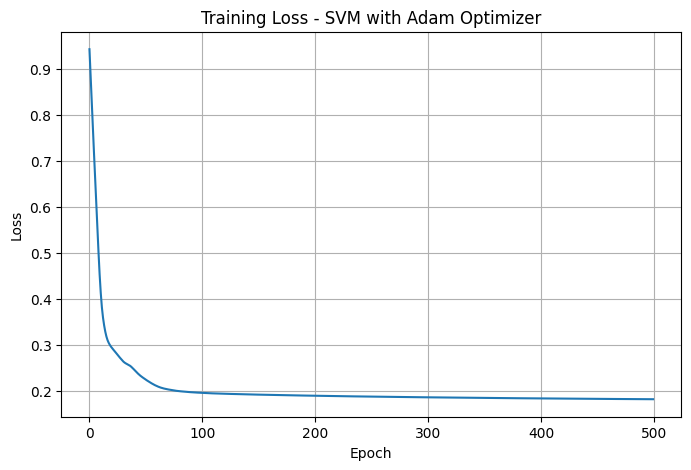

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss - SVM with Adam Optimizer")

plt.grid(True)
plt.show()

In [18]:
test_scores = predict_scores(K_test, alpha, bias)

y_pred = classes[np.argmax(test_scores, axis=1)]

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")

Test Accuracy: 0.9855072463768116
Test Accuracy (%): 98.55%


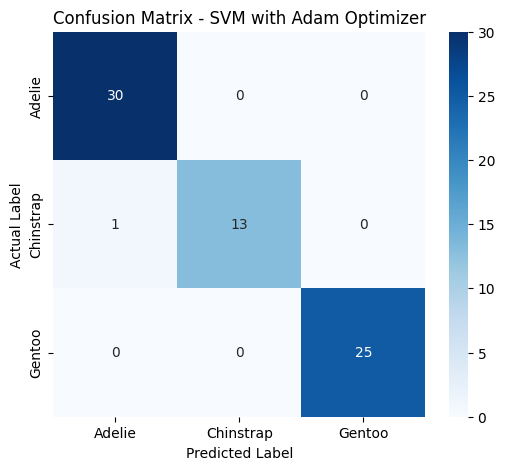

In [20]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - SVM with Adam Optimizer")

plt.show()

In [23]:
print("Classification Report - SVM with Adam Optimizer")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_
    )
)

Classification Report - SVM with Adam Optimizer
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69

